# Expensive coffee, richer farmers?
*Assignment 4 - Economics*

## Question 1: Understand and explore the market

**Data:** `coffee_market.csv` — 300 independent selling periods in a stylised wholesale market for one grade of green coffee (synthetic teaching data).

> Assumptions given in the brief: price-taking buyers and sellers, market clearing, fixed quality, no inventory carry-over. `growing_conditions` is independent of buyers' preferences, incomes and unobserved demand disturbances; `buyer_activity` does not directly change producers' costs.

### 1.1 First approach to data

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

coff_mark = pd.read_csv('data/coffee_market.csv')

# Colours (blue / orange / aqua) + different marker shapes, so groups never rely on colour alone
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
coff_mark.head()

,period_id,period_index,price_usd_kg,quantity_kt,growing_conditions,buyer_activity
0,M001,1,10.837531,133.302350,1.5,2.391855
1,M002,2,8.915661,67.150820,-1.5,-2.516137
2,M003,3,11.694981,88.019068,-1.5,-0.195789
3,M004,4,10.394216,101.971595,0.0,0.117742
4,M005,5,7.323098,95.714836,1.5,-1.148320


In [3]:
audit = pd.Series({
    "rows": len(coff_mark),
    "columns": coff_mark.shape[1],
    "missing cells": int(coff_mark.isna().sum().sum()),
    "duplicated rows": int(coff_mark.duplicated().sum()),
    "unique period_id": coff_mark["period_id"].nunique(),
    "period_id matches period_index": bool((coff_mark["period_id"].str[1:].astype(int) == coff_mark["period_index"]).all()),
    "non-positive prices": int((coff_mark["price_usd_kg"] <= 0).sum()),
    "non-positive quantities": int((coff_mark["quantity_kt"] <= 0).sum()),
    "distinct growing_conditions values": sorted(coff_mark["growing_conditions"].unique().tolist()),
    "distinct buyer_activity values": coff_mark["buyer_activity"].nunique(),
}, name="value")
display(audit.to_frame())
display(coff_mark.dtypes.to_frame("dtype"))
coff_mark["growing_conditions"].value_counts().sort_index().rename("periods").to_frame()

,value
rows,300
columns,6
missing cells,0
duplicated rows,0
unique period_id,300
period_id matches period_index,True
non-positive prices,0
non-positive quantities,0
distinct growing_conditions values,"[-1.5, 0.0, 1.5]"
distinct buyer_activity values,300


,dtype
period_id,str
period_index,int64
price_usd_kg,float64
quantity_kt,float64
growing_conditions,float64
buyer_activity,float64


,periods
growing_conditions,
-1.5,100
0.0,100
1.5,100


> The data is healthy and the description matches the content. No missing values or duplicated rows. In general is coherent as all prices and quantities are positive. This first step is fundamental so we can conclude all the analysis that's about to come represents behaviours and not data mistakes. 

**Important note**: Period id will not be analyzed as time because the description of the variable says "The index is not a historical trend". So time series are no part of this analysis.

### 1.2 Sales revenue and descriptive

Revenue = price × quantity. Units: (US\$ per kg) × (thousand tonnes) = (US\$/kg) × (10⁶ kg) = **million US\$** per selling period.

In [8]:
coff_mark["revenue_musd"] = coff_mark["price_usd_kg"] * coff_mark["quantity_kt"]

vars_ = {"price_usd_kg": "Price (US$/kg)",
         "quantity_kt": "Quantity (thousand t)",
         "revenue_musd": "Revenue (million US$)"}
desc = (coff_mark[list(vars_)].describe(percentiles=[.25, .5, .75]).T
          .rename(index=vars_)
          [["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])
desc["CV (std/mean)"] = desc["std"] / desc["mean"]
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,CV (std/mean)
Price (US$/kg),300.0,10.01,2.22,5.17,8.50,10.03,11.47,14.99,0.22
Quantity (thousand t),300.0,100.01,18.46,64.15,85.27,100.40,115.42,138.60,0.18
Revenue (million US$),300.0,1022.83,357.98,382.92,718.70,969.61,1300.92,1858.19,0.35


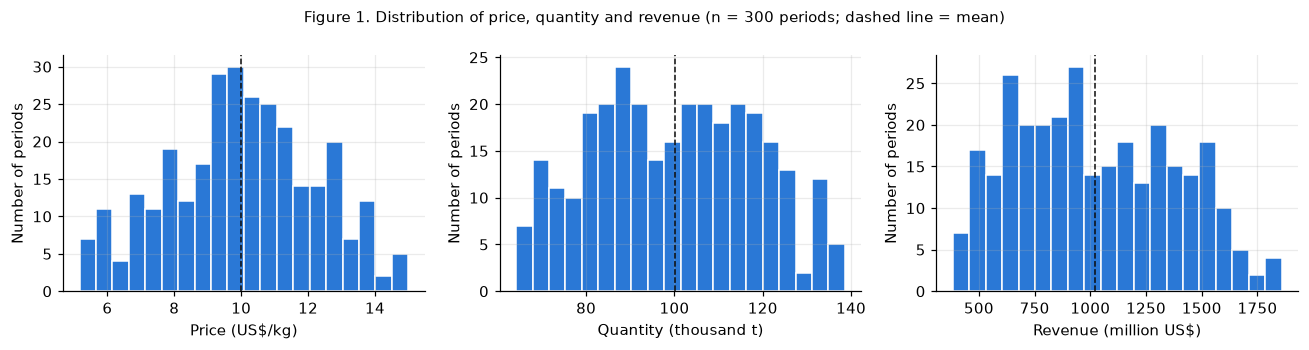

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (col, label) in zip(axes, vars_.items()):
    ax.hist(coff_mark[col], bins=20, color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(coff_mark[col].mean(), color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel(label); ax.set_ylabel("Number of periods")
fig.suptitle("Figure 1. Distribution of price, quantity and revenue (n = 300 periods; dashed line = mean)", fontsize=10)
fig.tight_layout(); plt.show()

Here we check for distribution (skew), outliers and variable fluctuation:
* The spread of the renvenue is much bigger than that from Price and Quantity: 35% vs 22% and 18% 
    * Typical price: 10 USD per kg
    * Typical quantity: 100 thousands of tonnes
    * Typical revenue: 1,022 million of USD
* We don't observe any extreme periods so far

### 1.3 Price-quantity relationship

We also fit the simplest linear relationship, $Q = a + b\,P$, treating all 300 points alike. This is the "naive" answer to *how does quantity move with price?*

Pooled fit: Q = 55.1 + 4.49·P   (kt per US$/kg)
Correlation(P, Q) = 0.54
'Elasticity' implied at the means (P̄=10.01, Q̄=100.0): 0.45


,n,P_mean,Q_mean
growing_conditions,,,
-1.5,100,11.57,91.69
0.0,100,10.20,102.04
1.5,100,8.25,106.31


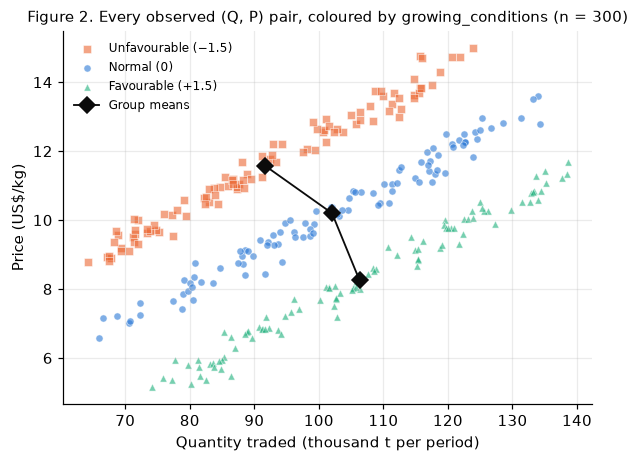

In [18]:
P, Q = coff_mark["price_usd_kg"], coff_mark["quantity_kt"]
b, a = np.polyfit(P, Q, 1)                       # Q = a + b*P
r = P.corr(Q)
naive_elast = b * P.mean() / Q.mean()            # slope × (P̄ / Q̄)

print(f"Pooled fit: Q = {a:.1f} + {b:.2f}·P   (kt per US$/kg)")
print(f"Correlation(P, Q) = {r:.2f}")
print(f"'Elasticity' implied at the means (P̄={P.mean():.2f}, Q̄={Q.mean():.1f}): {naive_elast:.2f}")

# Same points, coloured by growing_conditions (supply shifter), plus each group's mean
groups = {-1.5: ("Unfavourable (−1.5)", ORANGE, "s"), 0.0: ("Normal (0)", BLUE, "o"), 1.5: ("Favourable (+1.5)", AQUA, "^")}
means = (coff_mark.groupby("growing_conditions")
           .agg(n=("price_usd_kg", "size"), P_mean=("price_usd_kg", "mean"), Q_mean=("quantity_kt", "mean")))
display(means.round(2))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for g, (label, col, mk) in groups.items():
    sub = coff_mark[coff_mark["growing_conditions"] == g]
    ax.scatter(sub["quantity_kt"], sub["price_usd_kg"], s=22, color=col, marker=mk,
               alpha=0.6, edgecolor="white", linewidth=0.5, label=label)
ax.plot(means["Q_mean"], means["P_mean"], color=INK, marker="D", markersize=7, linewidth=1.2, label="Group means")
ax.set_xlabel("Quantity traded (thousand t per period)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 2. Every observed (Q, P) pair, coloured by growing_conditions (n = 300)", fontsize=10)
ax.legend(frameon=False, loc="upper left", fontsize=8); plt.show()

**What do we see when we colour the dots by `growing_conditions` (Figure 2)?**

> **First conclusion:** As the price increases, the quantity traded decreases. But it's not an isolated effect

* The graph was initially analyzed with an overall mean, but it does not make that much sense after plotting: The three groups of `growing_conditions` have clearly different behaviours

- **The cloud is really three bands.** Each harvest level forms its own narrow, upward-sloping band, and the bands are stacked side by side. What looks like a noisy pooled relationship (correlation 0.54) is mostly the mix of three different harvest situations.

- **Better harvests sit lower and further right.** The same price comes with more coffee traded when growing conditions are good. This is what we would expect if good weather shifts supply outward.

- **Within each band, price and quantity rise together.** Growing conditions are fixed inside a band, so this co-movement must come from the other driver, `buyer_activity` (demand shifting along a given supply).

- **The group means move the opposite way.** Going from poor to good harvests, the average price falls (11.57 → 10.20 → 8.25 US\$/kg) while the average quantity rises (91.7 → 102.0 → 106.3 kt). Since `growing_conditions` is independent of buyers, average demand is the same in all three groups. The diamonds therefore show how buyers react when only supply changes: cheaper coffee, more bought.

In [13]:
cols = ["price_usd_kg", "quantity_kt", "revenue_musd", "growing_conditions", "buyer_activity"]
coff_mark[cols].corr().round(2)

,price_usd_kg,quantity_kt,revenue_musd,growing_conditions,buyer_activity
price_usd_kg,1.00,0.54,0.89,-0.61,0.79
quantity_kt,0.54,1.00,0.85,0.32,0.93
revenue_musd,0.89,0.85,1.00,-0.21,0.97
growing_conditions,-0.61,0.32,-0.21,1.00,-0.02
buyer_activity,0.79,0.93,0.97,-0.02,1.00


> Price and quantity are both strongly correlated with `buyer_activity`
>
> `growing_conditions` correlates *negatively* with price but *positively* with quantity. Simpler words: positive grow conditions establish an scenario for cheaper and more abundant coffee.

In [17]:
by_gc = (coff_mark.groupby("growing_conditions")
           .agg(periods=("price_usd_kg", "size"),
                mean_price=("price_usd_kg", "mean"),
                mean_quantity=("quantity_kt", "mean"),
                mean_revenue=("revenue_musd", "mean"),
                mean_buyer_activity=("buyer_activity", "mean"))
           .rename(index={-1.5: "Unfavourable (−1.5)", 0.0: "Normal (0)", 1.5: "Favourable (+1.5)"}))
by_gc.round(2)

,periods,mean_price,mean_quantity,mean_revenue,mean_buyer_activity
growing_conditions,,,,,
Unfavourable (−1.5),100,11.57,91.69,1088.90,-0.07
Normal (0),100,10.20,102.04,1070.36,0.20
Favourable (+1.5),100,8.25,106.31,909.22,-0.15


> Revenue is higher when the growing conditions are worse: High price, low quantity
>
> `growing_conditions` correlates *negatively* with price but *positively* with quantity. Simpler words: positive grow conditions establish an scenario for cheaper and more abundant coffee.

---
# Question 2: Develop an equilibrium explanation

## 2.1 What an observed (Q, P) pair represents

In each selling period there is a demand curve $D(p; \text{buyer activity}, u_t)$ and a supply curve $S(p; \text{growing conditions}, v_t)$, where $u_t$ and $v_t$ are disturbances we **do not observe**. With price-taking and market clearing, the recorded pair $(Q_t, P_t)$ solves

$$D(P_t;\ \text{buyer activity}_t,\ u_t) \;=\; S(P_t;\ \text{growing conditions}_t,\ v_t) \;=\; Q_t .$$

So each row is the **intersection** of two curves. It is not a point that buyers picked on their own, and it is not one that sellers picked on their own.

**Movement along a curve and shift of a curve**
- *Movement along* a curve: the price changes while everything else in that curve's equation stays fixed (same buyer activity and same $u_t$ for demand). That is the thing we want to measure: "if the price rose, how much less would buyers purchase?"
- *Shift* of a curve: one of the conditions behind it changes (buyer activity, growing conditions, or an unobserved disturbance), so the whole curve moves. At **every** price, the quantity is different.

## 2.2 Two alternative explanations for a higher coffee price

| | **Explanation A: stronger demand** | **Explanation B: weaker supply (bad harvest)** |
|---|---|---|
| What changes | `buyer_activity` ↑: foreign buyers want more at every price | `growing_conditions` ↓: less coffee is worth harvesting at every price |
| Curve that shifts | Demand shifts **right** | Supply shifts **left** |
| Movement along | the **unchanged supply** curve | the **unchanged demand** curve |
| Price | ↑ | ↑ |
| Quantity | **↑** | **↓** |
| Seller revenue | ↑ (P and Q both rise) | ambiguous: depends on how strongly buyers react to price |

**Key:** the price rises in both cases, so the price alone cannot tell the two explanations apart. The direction of the **quantity** change can.

> The diagrams below use *illustrative* linear curves in coffee-like units. They are not estimates

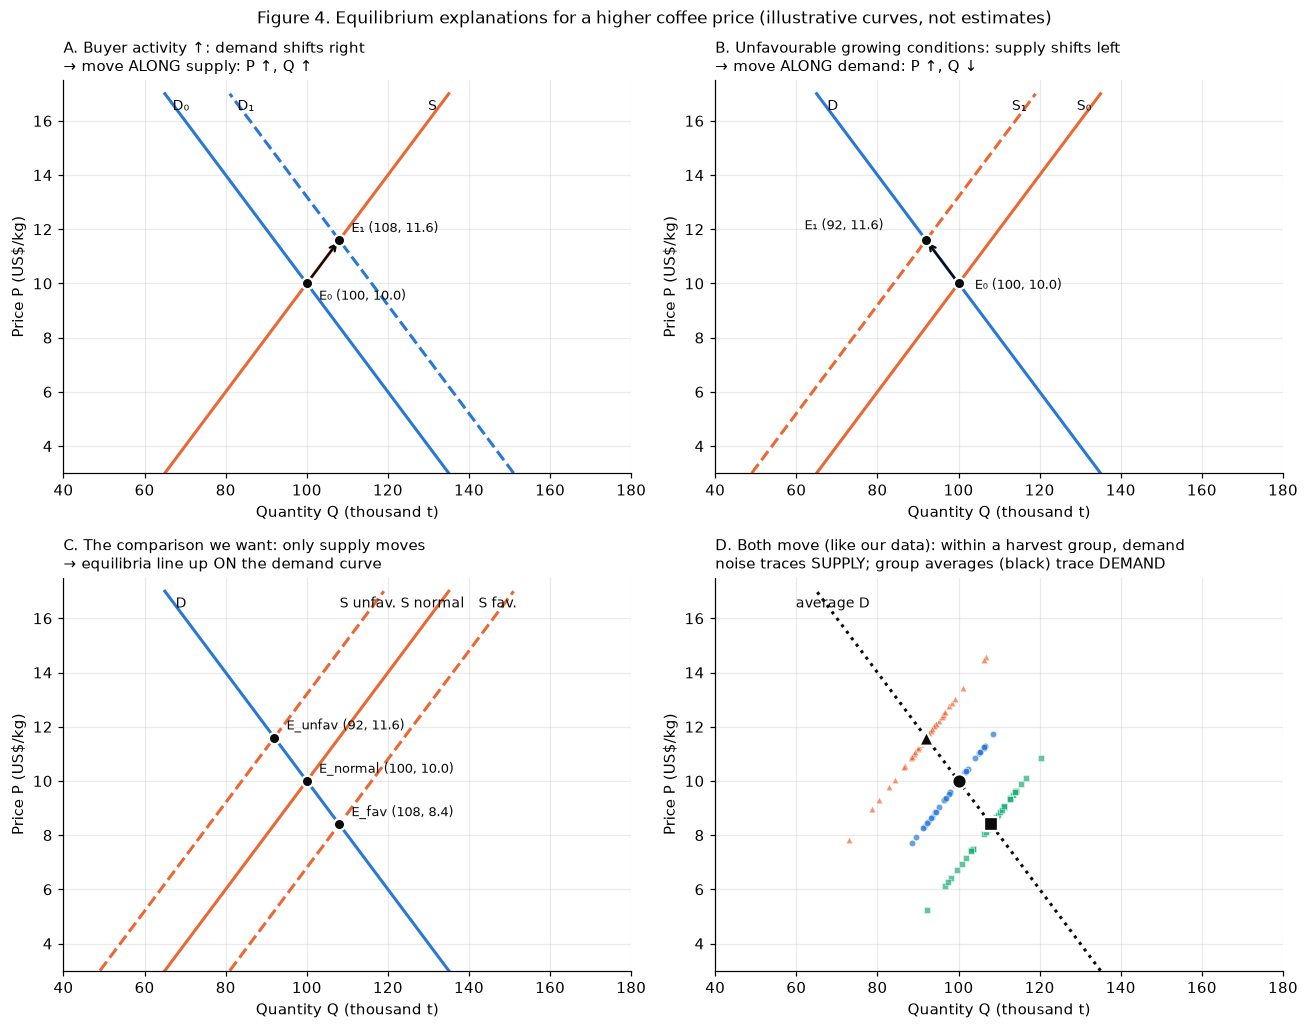

In [19]:
def demand(P, shift=0):  return 150 + shift - 5 * P     # illustrative only
def supply(P, shift=0):  return 50 + shift + 5 * P      # illustrative only
def eq(dS=0, dD=0):      # solve 150+dD-5P = 50+dS+5P
    P = (100 + dD - dS) / 10
    return demand(P, dD), P

Pg = np.linspace(3, 17, 100)
def curve(ax, f, shift, color, label, ls="-"):
    ax.plot(f(Pg, shift), Pg, color=color, lw=2, ls=ls)
    q = f(16.2, shift); ax.text(q, 16.4, label, color=INK, fontsize=9, ha="center")
def point(ax, Q, P, name, dx=3, dy=-0.6):
    ax.scatter([Q], [P], s=55, color=INK, zorder=5, edgecolor="white", linewidth=1.5)
    ax.text(Q + dx, P + dy, f"{name} ({Q:.0f}, {P:.1f})", fontsize=8.5, color=INK)
def frame(ax, title):
    ax.set_xlim(40, 180); ax.set_ylim(3, 17.5)
    ax.set_xlabel("Quantity Q (thousand t)"); ax.set_ylabel("Price P (US$/kg)")
    ax.set_title(title, fontsize=10, loc="left")

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))

# A: demand shift
ax = axes[0, 0]
curve(ax, supply, 0, ORANGE, "S")
curve(ax, demand, 0, BLUE, "D₀"); curve(ax, demand, 16, BLUE, "D₁", ls="--")
Q0, P0 = eq(); Q1, P1 = eq(dD=16)
point(ax, Q0, P0, "E₀"); point(ax, Q1, P1, "E₁", dy=0.3)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "A. Buyer activity ↑: demand shifts right\n→ move ALONG supply: P ↑, Q ↑")

# B: supply shift
ax = axes[0, 1]
curve(ax, demand, 0, BLUE, "D")
curve(ax, supply, 0, ORANGE, "S₀"); curve(ax, supply, -16, ORANGE, "S₁", ls="--")
Q1, P1 = eq(dS=-16)
point(ax, Q0, P0, "E₀", dx=4, dy=-0.2); point(ax, Q1, P1, "E₁", dx=-30, dy=0.4)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "B. Unfavourable growing conditions: supply shifts left\n→ move ALONG demand: P ↑, Q ↓")

# C: supply shifts only, demand fixed -> equilibria trace demand
ax = axes[1, 0]
curve(ax, demand, 0, BLUE, "D")
for s, lab in [(-16, "S unfav."), (0, "S normal"), (16, "S fav.")]:
    curve(ax, supply, s, ORANGE, lab, ls="-" if s == 0 else "--")
pts = [eq(dS=s) for s in (-16, 0, 16)]
for (q, p), lab in zip(pts, ["E_unfav", "E_normal", "E_fav"]):
    point(ax, q, p, lab, dx=3, dy=0.3)
frame(ax, "C. The comparison we want: only supply moves\n→ equilibria line up ON the demand curve")

# D: both shift -> each supply curve traced by demand noise
ax = axes[1, 1]
rng = np.random.default_rng(1)
for s, colr, mk in [(-16, ORANGE, "^"), (0, BLUE, "o"), (16, AQUA, "s")]:
    dshift = rng.normal(0, 14, 40)
    qs, ps = zip(*[eq(dS=s, dD=d) for d in dshift])
    ax.scatter(qs, ps, s=18, color=colr, marker=mk, alpha=0.7, edgecolor="white", linewidth=0.4)
    q, p = eq(dS=s); ax.scatter([q], [p], s=90, color=INK, marker=mk, zorder=5, edgecolor="white", linewidth=1.5)
curve(ax, demand, 0, INK, "average D", ls=":")
frame(ax, "D. Both move (like our data): within a harvest group, demand\nnoise traces SUPPLY; group averages (black) trace DEMAND")

fig.suptitle("Figure 4. Equilibrium explanations for a higher coffee price (illustrative curves, not estimates)", fontsize=11)
fig.tight_layout(); plt.show()

## 2.3 The proposed comparison

Compare market outcomes **across growing-conditions groups** (unfavourable −1.5, normal 0, favourable +1.5), using each group's **average** price and quantity. The change in average quantity divided by the change in average price, between harvest groups, measures how buyers respond to price: a movement along demand.

**It is informative** because growing conditions shift **supply only**. Comparing harvest groups therefore moves the market *along* the demand curve, exactly as in panel C.

| | |
|---|---|
| **What changes across the groups** | Growing conditions → the supply curve → equilibrium price (and, through it, quantity). |
| **What must remain comparable** | Everything behind demand: buyer activity, buyers' incomes and preferences, outside options, and the *unobserved* demand disturbances $u_t$. Also the product (fixed quality) and the market (same buyers and sellers). |
| **Assumptions that justify it** | (1) **Relevance**: growing conditions really shift supply, so prices differ across groups. (2) **Exclusion**: growing conditions affect buyers only through the price; they do not enter the demand curve. (3) **Independence**: growing conditions are unrelated to buyer activity and to unobserved demand shocks.  (4) A **stable demand curve**, approximately linear over the observed range. |

## 2.4 What if demand also moves for reasons we do not observe?

Demand disturbances $u_t$ do not ruin the comparison, as long as they are **unrelated to growing conditions**:
- In any single period, demand noise moves the point off the "average" demand curve, so one period on its own tells us little.
- But weather does not "know" what buyers are doing. Each harvest group is therefore a mix of good, normal and bad demand periods, **in the same proportions** on average. Averaging within each group cancels the demand noise (black markers in panel D), and the remaining difference between group averages is caused by supply.

**When it would fail:**
- If growing conditions were correlated with demand. For example, a weather event that also hits buyers' economies, or buyers who stockpile when they hear about a bad harvest.
- If groups were too small for the averaging to work. Here we have 100 periods per group.
- If supply shifted for other reasons that happen to coincide with demand shocks.

---
# Question 3: Measure the demand response

## 3.1 The idea

Weather moves the market **along** the demand curve (Q2, panel C). So:

$$\text{demand slope} \;=\; \frac{\Delta\ \text{average quantity across harvest groups}}{\Delta\ \text{average price across harvest groups}} \quad [\text{kt per US\$/kg}]$$

We implement this in two versions:
1. **Simple comparison:** raw group means, unfavourable versus favourable harvest. No modelling at all.
2. **Adjusted comparison:** the same ratio after removing the part of each group's P and Q explained by the *observed* demand shifter `buyer_activity`. Buyer activity is independent of the weather, so this does not change *what* we measure. It removes noise and the small chance imbalances between groups.

In [20]:
gm = coff_mark.groupby("growing_conditions")[["price_usd_kg", "quantity_kt", "buyer_activity"]].mean()
dQ = gm.loc[-1.5, "quantity_kt"] - gm.loc[1.5, "quantity_kt"]
dP = gm.loc[-1.5, "price_usd_kg"] - gm.loc[1.5, "price_usd_kg"]
slope_simple = dQ / dP
print("Unfavourable vs favourable harvest (raw group means):")
print(f"  ΔQ = {dQ:.2f} kt,  ΔP = {dP:.2f} US$/kg  →  slope = {slope_simple:.2f} kt per US$/kg")

Unfavourable vs favourable harvest (raw group means):
  ΔQ = -14.63 kt,  ΔP = 3.32 US$/kg  →  slope = -4.40 kt per US$/kg


### Adjusting for observed buyer activity

For each harvest group we fit two straight lines, quantity on buyer activity and price on buyer activity, and read off the predicted Q and P **at buyer_activity = 0** (reference demand conditions). This gives three equilibria with the observed demand conditions held fixed at the same level.

Doing all three groups at once is equivalent to two regressions, each with the weather and buyer activity as regressors:
- $Q = \alpha_Q + \gamma_Q\,G + \delta_Q\,B$
- $P = \alpha_P + \gamma_P\,G + \delta_P\,B$

$\gamma_Q$ is how much **quantity** moves when the weather improves by one point, and $\gamma_P$ is how much **price** moves for the same improvement. Because the weather only moves supply, their ratio $\gamma_Q/\gamma_P$ is the demand slope.

In [ ]:
def ols(y, *xs):
    X = np.column_stack([np.ones(len(y)), *xs])
    return np.linalg.lstsq(X, y, rcond=None)[0]

def demand_slope(d, adjust=True):
    G, B = d["growing_conditions"], d["buyer_activity"]
    if adjust:
        gQ = ols(d["quantity_kt"], G, B)[1]; gP = ols(d["price_usd_kg"], G, B)[1]
    else:
        gQ = ols(d["quantity_kt"], G)[1];    gP = ols(d["price_usd_kg"], G)[1]
    return gQ / gP

cQ = ols(df["quantity_kt"], df["growing_conditions"], df["buyer_activity"])
cP = ols(df["price_usd_kg"], df["growing_conditions"], df["buyer_activity"])
slope_adj = cQ[1] / cP[1]
print(f"Weather effect on Q: {cQ[1]:+.2f} kt per point of growing conditions")
print(f"Weather effect on P: {cP[1]:+.2f} US$/kg per point of growing conditions")
print(f"Adjusted demand slope = {cQ[1]:.2f} / {cP[1]:.2f} = {slope_adj:.2f} kt per US$/kg")

# adjusted group equilibria at buyer_activity = 0
adj = pd.DataFrame({g: {"Q at B=0": ols(d["quantity_kt"], d["buyer_activity"])[0],
                        "P at B=0": ols(d["price_usd_kg"], d["buyer_activity"])[0]}
                    for g, d in df.groupby("growing_conditions")}).T
adj.index.name = "growing_conditions"
adj.round(2)

Weather effect on Q: +5.16 kt per point of growing conditions
Weather effect on P: -1.08 US$/kg per point of growing conditions
Adjusted demand slope = 5.16 / -1.08 = -4.78 kt per US$/kg


,Q at B=0,P at B=0
growing_conditions,,
-1.5,92.34,11.64
0.0,99.95,9.99
1.5,107.86,8.40


In [ ]:
coff_ep = pd.read_csv('data/coffee_episodes.csv')
coff_for = pd.read_csv('data/coffee_forecast_reveal.csv')
coff_for_sc = pd.read_csv('data/coffee_forecast_scenarios.csv')